In [1]:
import pandas as pd


In [2]:
from pathlib import Path
import pandas as pd

violation_dir = Path(
    "/Users/adamswietek/Documents/NDSC_HiddenHousing/"
    "data/01_source/violations/Raw Data"
)

violations = pd.concat(
    [
        pd.read_csv(
            csv_path,
            dtype=str,
            low_memory=False,
        ).assign(
            source_file=csv_path.name,
            source_year=int(csv_path.name[:4]),
        )
        for csv_path in sorted(violation_dir.glob("*.csv"))
    ],
    ignore_index=True,
    sort=False,
)

print(violations.shape)
# violations.head()

(560730, 24)


In [3]:
violations.columns

Index(['APN', 'Total Violations', 'Active Violations', 'Case No.', 'Case Type',
       'Inspection Date', 'Council District', 'Unit Count', 'Site Address',
       'City', 'Zip', 'year', 'source_file', 'source_year', 'apn',
       'TotalViolations', 'UnresolvedViolations', 'CaseType', 'crisCaseID',
       'inspDate', 'UnitCnt', 'SiteAddress', 'councildist', 'UnitCnt.1'],
      dtype='object')

In [4]:
violations['source_year'].value_counts().sort_index()# counts across years
violations.groupby('source_year')['APN'].nunique().sort_index() #unique APNs across years
violations.groupby('APN')['year'].nunique().value_counts() #unique Year across APNs


year
4     34825
3     27701
5     16861
1      9301
2      8430
6      7590
7      3679
8      1931
9      1010
10      582
11      384
12      211
13      125
14       72
15       36
16       22
17        3
Name: count, dtype: int64

In [5]:
violations.columns

Index(['APN', 'Total Violations', 'Active Violations', 'Case No.', 'Case Type',
       'Inspection Date', 'Council District', 'Unit Count', 'Site Address',
       'City', 'Zip', 'year', 'source_file', 'source_year', 'apn',
       'TotalViolations', 'UnresolvedViolations', 'CaseType', 'crisCaseID',
       'inspDate', 'UnitCnt', 'SiteAddress', 'councildist', 'UnitCnt.1'],
      dtype='object')

In [6]:
violations['Case Type'].value_counts()#/violations.shape[0]

Case Type
SCEP                 353875
Complaint            151606
HOME                   3787
Residential Hotel      1335
Tier 2                 1298
Task Force              797
Name: count, dtype: int64

In [7]:
complaint_fp = '/Users/adamswietek/Documents/NDSC_HiddenHousing/data/01_source/violations/violations-2_with_nature_of_complaint_taxonomy_status (2).csv'

complaints = pd.read_csv(complaint_fp)
complaints.shape

(170714, 28)

In [8]:
violations.columns

Index(['APN', 'Total Violations', 'Active Violations', 'Case No.', 'Case Type',
       'Inspection Date', 'Council District', 'Unit Count', 'Site Address',
       'City', 'Zip', 'year', 'source_file', 'source_year', 'apn',
       'TotalViolations', 'UnresolvedViolations', 'CaseType', 'crisCaseID',
       'inspDate', 'UnitCnt', 'SiteAddress', 'councildist', 'UnitCnt.1'],
      dtype='object')

In [9]:
violations[['case_']]

KeyError: "None of [Index(['case_'], dtype='object')] are in the [columns]"

In [10]:
complaints.case_type.value_counts()

case_type
Complaint    170697
Legal             2
Name: count, dtype: int64

In [11]:
complaints[['case_id','AIN','census_tract']].nunique()

case_id         170530
AIN              52259
census_tract      1051
dtype: int64

In [12]:
complaints.nature_of_complaint.value_counts().head(10)

nature_of_complaint
Construction in progress without permits                                                    4733
Construction performed without permits                                                      3181
Change of use/occupancy without Building permit and Certificate of Occupancy                2764
Room heating appliance missing or defective                                                 2056
Plaster/drywall wall/ceiling covering defective, deteriorated, or paint is peeling          1913
Premises not maintained in a safe and sanitary condition                                    1887
Lack of adequate flow of hot and/or cold running water                                      1845
Trash, debris, and/or discard items stored on premises                                      1741
Unapproved Unit(s)                                                                          1603
Windows, doors, cabinets, and frames not operable, defective, missing, and/or unsanitary    1554
Name: coun

In [13]:
complaints.complaint_category.value_counts().head(10)

complaint_category
not_unpermitted_related     120987
work_without_permits         20007
other_unpermitted             8915
unapproved_trade_work         8374
unapproved_unit               6740
change_of_use                 4891
unpermitted_construction       435
garage_conversion              186
illegal_business_use           103
unpermitted_addition            49
Name: count, dtype: int64

In [14]:
complaints.status_bucket.value_counts()

status_bucket
closed                    133485
appeal_or_outreach         13285
in_progress                 8189
resolved                    8026
no_violations_observed      6955
escalated                    719
other                         40
Name: count, dtype: int64

In [15]:
complaints[['relates_to_unpermitted_structure','dwelling_specific','order_issued_ever']].mean()

relates_to_unpermitted_structure    0.291200
dwelling_specific                   0.041578
order_issued_ever                   0.416902
dtype: float64

In [16]:
complaints['first_year'] = pd.to_datetime(complaints['activity_first_date']).dt.year
complaints['last_year'] = pd.to_datetime(complaints['activity_last_date']).dt.year

#.value_counts()

/var/folders/7b/rl6lkdns1dbfv_n3wwwmq8580000gn/T/ipykernel_12513/1085775381.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  complaints['first_year'] = pd.to_datetime(complaints['activity_first_date']).dt.year


<Axes: xlabel='last_year'>

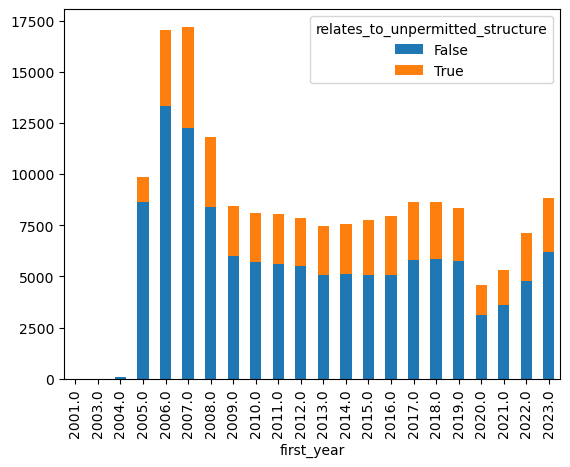

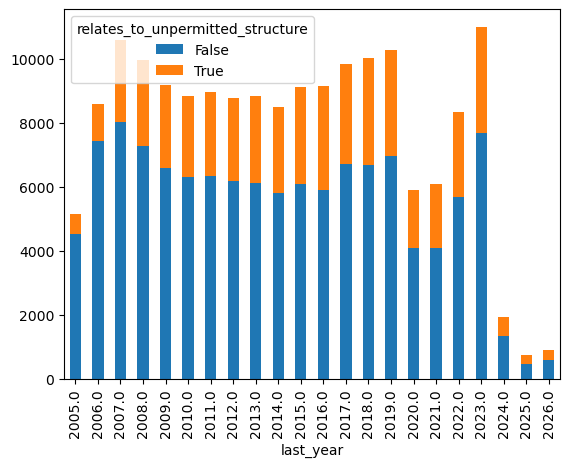

In [17]:
complaints.groupby(['first_year','relates_to_unpermitted_structure']).size().unstack().plot.bar(stacked=True)
complaints.groupby(['last_year','relates_to_unpermitted_structure']).size().unstack().plot.bar(stacked=True)

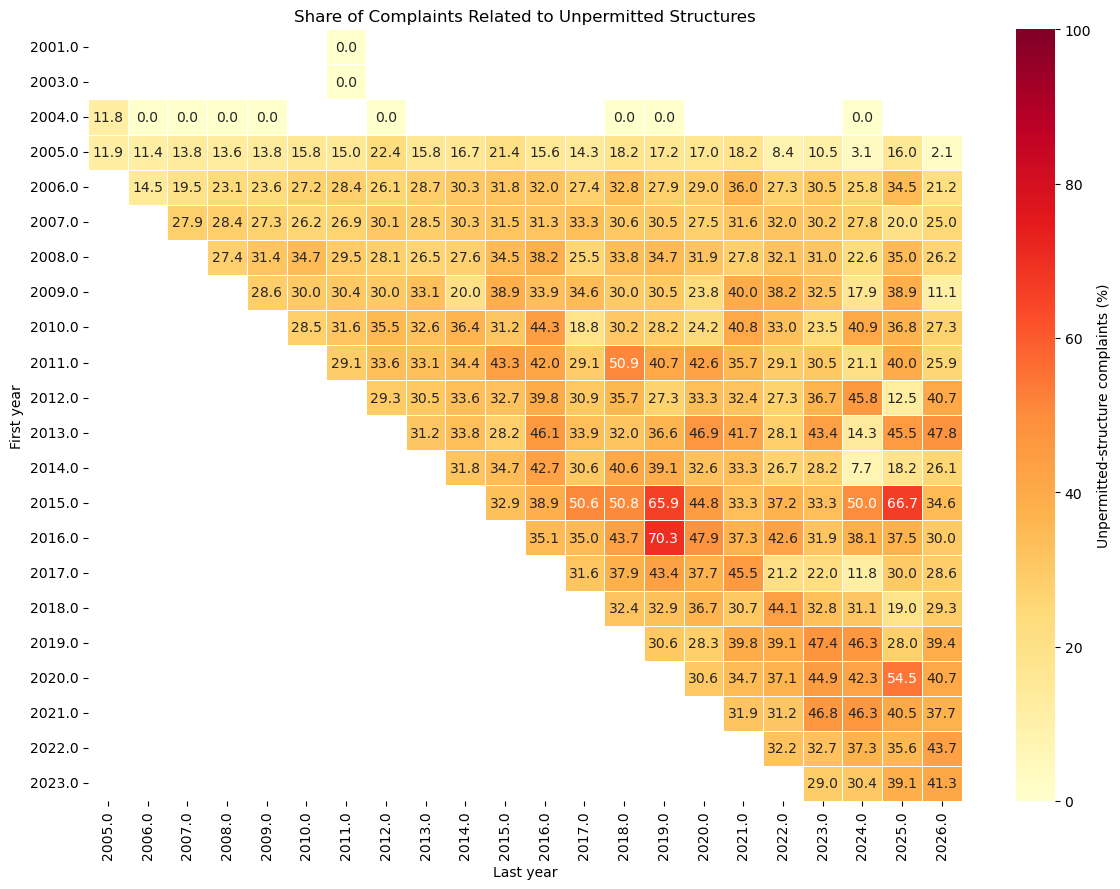

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

heatmap_data = (
    complaints
    .groupby(["first_year", "last_year"])
    ["relates_to_unpermitted_structure"]
    .mean()
    .unstack()
    .mul(100)
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Unpermitted-structure complaints (%)"},
)

plt.title("Share of Complaints Related to Unpermitted Structures")
plt.xlabel("Last year")
plt.ylabel("First year")
plt.tight_layout()
plt.show()

## IRS 2022 ZIP-level income proxy

Use IRS Statistics of Income ZIP Code data as a keyless income proxy. For each California ZIP, mean AGI per return is calculated as total adjusted gross income divided by the number of returns. IRS money amounts are reported in thousands of dollars, so AGI is multiplied by 1,000 before division.

This is a 2022 cross-sectional ZIP-level proxy—not tract-level income in the complaint year. ZIP `99999` is an IRS non-geographic residual category and is retained only to reproduce the broad match count; use `irs_zip_is_geographic` for spatial analysis.

In [146]:
from pathlib import Path

import requests

IRS_CA_2022_URL = 'https://www.irs.gov/pub/irs-soi/22zp05ca.xlsx'
IRS_CA_2022_CACHE = Path(
    '/Users/adamswietek/Documents/NDSC_HiddenHousing/'
    'data/01_source/irs/22zp05ca.xlsx'
)


def load_irs_2022_ca_zip_income(
    cache_path=IRS_CA_2022_CACHE,
    url=IRS_CA_2022_URL,
):
    """Load IRS 2022 California ZIP data and calculate mean AGI/return."""
    cache_path = Path(cache_path)
    if not cache_path.exists():
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        response = requests.get(url, timeout=120)
        response.raise_for_status()
        cache_path.write_bytes(response.content)

    raw = pd.read_excel(cache_path, header=3)
    zip_col = 'ZIP\ncode [1]'
    bracket_col = 'Size of adjusted gross income'
    returns_col = 'Number of returns [2]'
    agi_col = 'Adjusted gross income (AGI) [7]'

    # A blank AGI-bracket value identifies the total row for each ZIP.
    totals = raw.loc[
        raw[bracket_col].isna(),
        [zip_col, returns_col, agi_col],
    ].copy()
    totals['zip_numeric'] = pd.to_numeric(totals[zip_col], errors='coerce')
    totals = totals.loc[totals['zip_numeric'].notna()].copy()
    totals['zip5'] = (
        totals['zip_numeric'].astype(int).astype(str).str.zfill(5)
    )
    totals['irs_returns_2022'] = pd.to_numeric(
        totals[returns_col], errors='coerce'
    )
    totals['irs_agi_thousands_2022'] = pd.to_numeric(
        totals[agi_col], errors='coerce'
    )
    totals['irs_mean_agi_per_return_2022'] = (
        totals['irs_agi_thousands_2022'].mul(1_000)
        / totals['irs_returns_2022']
    )
    totals['irs_zip_is_geographic'] = totals['zip5'].ne('99999')

    result = totals[[
        'zip5', 'irs_returns_2022', 'irs_agi_thousands_2022',
        'irs_mean_agi_per_return_2022', 'irs_zip_is_geographic',
    ]].copy()
    assert result['zip5'].is_unique
    return result


irs_zip_income_2022 = load_irs_2022_ca_zip_income()
print(f'IRS California ZIP records: {len(irs_zip_income_2022):,}')
irs_zip_income_2022.head()

IRS California ZIP records: 1,476


,zip5,irs_returns_2022,irs_agi_thousands_2022,irs_mean_agi_per_return_2022,irs_zip_is_geographic
10,90001,22540.0,869773.0,38587.976930,True
18,90002,21180.0,807847.0,38141.973560,True
26,90003,28580.0,1029206.0,36011.406578,True
34,90004,27970.0,2650372.0,94757.668931,True
42,90005,17480.0,1270734.0,72696.453089,True


In [147]:
# Extract the final five-digit ZIP from the standardized LAHD address.
complaints['zip5'] = (
    complaints['official_address'].astype('string').str.strip()
    .str.extract(r'\b(\d{5})(?:-\d{4})?\s*$', expand=False)
)

irs_columns = [
    'irs_returns_2022', 'irs_agi_thousands_2022',
    'irs_mean_agi_per_return_2022', 'irs_zip_is_geographic',
]
complaints = complaints.drop(columns=irs_columns, errors='ignore').merge(
    irs_zip_income_2022, on='zip5', how='left', validate='m:1'
)
complaints['irs_income_matched_2022'] = (
    complaints['irs_mean_agi_per_return_2022'].notna()
)
geographic_irs_match = complaints['irs_zip_is_geographic'].eq(True)

irs_match_summary = pd.DataFrame([
    {
        'stage': 'All complaint records',
        'records': len(complaints),
        'unique_cases': complaints['case_id'].nunique(),
        'unique_AINs': complaints['AIN'].nunique(),
    },
    {
        'stage': 'IRS income matched (including ZIP 99999)',
        'records': complaints['irs_income_matched_2022'].sum(),
        'unique_cases': complaints.loc[
            complaints['irs_income_matched_2022'], 'case_id'
        ].nunique(),
        'unique_AINs': complaints.loc[
            complaints['irs_income_matched_2022'], 'AIN'
        ].nunique(),
    },
    {
        'stage': 'IRS income matched to geographic ZIP',
        'records': geographic_irs_match.sum(),
        'unique_cases': complaints.loc[
            geographic_irs_match, 'case_id'
        ].nunique(),
        'unique_AINs': complaints.loc[
            geographic_irs_match, 'AIN'
        ].nunique(),
    },
])

display(irs_match_summary.style.format({
    'records': '{:,.0f}',
    'unique_cases': '{:,.0f}',
    'unique_AINs': '{:,.0f}',
}))

,stage,records,unique_cases,unique_AINs
0,All complaint records,"170,714","170,530","52,259"
1,IRS income matched (including ZIP 99999),"163,497","163,319","49,877"
2,IRS income matched to geographic ZIP,"163,485","163,307","49,872"


In [148]:
complaints[[
    'case_id', 'AIN', 'zip5', 'irs_mean_agi_per_return_2022',
    'irs_income_matched_2022', 'irs_zip_is_geographic',
]].head()

,case_id,AIN,zip5,irs_mean_agi_per_return_2022,irs_income_matched_2022,irs_zip_is_geographic
0,1017,4103004001,90045,158219.060623,True,True
1,1028,4227003006,90291,183052.719362,True,True
2,1032,7451034021,90731,72703.259648,True,True
3,665,4116002050,90293,157352.785924,True,True
4,1029,4128010008,90045,158219.060623,True,True


Text(0, 0.5, 'Share of complaints that are dwelling-specific')

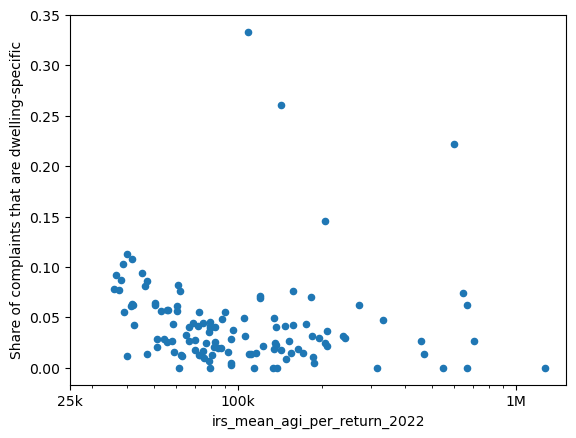

In [149]:
complaints.groupby('zip5')[['irs_mean_agi_per_return_2022','dwelling_specific']].mean().plot.scatter(x = 'irs_mean_agi_per_return_2022', y = 'dwelling_specific', logx=True)

plt.xticks([25_000,100_000,1_000_000],['25k','100k','1M'])
plt.ylabel('Share of complaints that are dwelling-specific')

Text(0, 0.5, 'Share of complaints that are dwelling-specific')

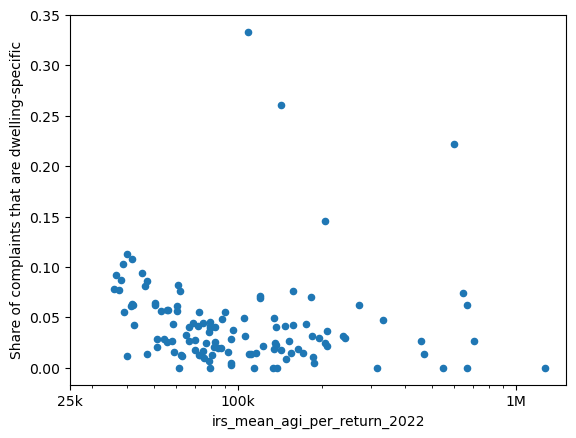

In [150]:
complaints.groupby('zip5')[['irs_mean_agi_per_return_2022','dwelling_specific']].mean().plot.scatter(x = 'irs_mean_agi_per_return_2022', y = 'dwelling_specific', logx=True)

plt.xticks([25_000,100_000,1_000_000],['25k','100k','1M'])
plt.ylabel('Share of complaints that are dwelling-specific')

In [167]:
non_udu = (complaints
                  .query('relates_to_unpermitted_structure == True')

.query('dwelling_specific == True')
.query('no_violations_observed_ever == True'))

In [168]:
udu = (complaints
       .query('relates_to_unpermitted_structure == True')
.query('dwelling_specific == True')
.query('order_issued_ever == True'))

In [169]:
udu.shape, non_udu.shape

((2656, 36), (3918, 36))

In [170]:
non_udu.nature_of_complaint.value_counts().head(10)

nature_of_complaint
Unapproved Unit(s)                                                                                                                          969
Unapproved Unit(s), Change of use/occupancy without Building permit and Certificate of Occupancy                                            302
Construction performed without permits, Unapproved Unit(s)                                                                                  215
Unapproved Unit(s), Construction performed without permits                                                                                  198
Change of use/occupancy without Building permit and Certificate of Occupancy, Unapproved Unit(s)                                            195
Construction performed without permits, Unapproved Unit(s), Change of use/occupancy without Building permit and Certificate of Occupancy    178
Unapproved Unit(s), Change of use/occupancy without Building permit and Certificate of Occupancy, Construction perfo

In [171]:
udu.nature_of_complaint.value_counts().head(10).index.tolist()

['Unapproved Unit(s)',
 'Unapproved Unit(s), Change of use/occupancy without Building permit and Certificate of Occupancy',
 'Change of use/occupancy without Building permit and Certificate of Occupancy, Unapproved Unit(s)',
 'Construction performed without permits, Unapproved Unit(s), Change of use/occupancy without Building permit and Certificate of Occupancy',
 'Construction performed without permits, Unapproved Unit(s)',
 'Unapproved Unit(s), Construction performed without permits',
 'Unapproved Unit(s), Change of use/occupancy without Building permit and Certificate of Occupancy, Construction performed without permits',
 'Change of use/occupancy without Building permit and Certificate of Occupancy, Unapproved Unit(s), Construction performed without permits',
 'Construction in progress without permits, Unapproved Unit(s)',
 'Unapproved Unit(s), Construction performed without permits, Change of use/occupancy without Building permit and Certificate of Occupancy']

<Axes: xlabel='first_year'>

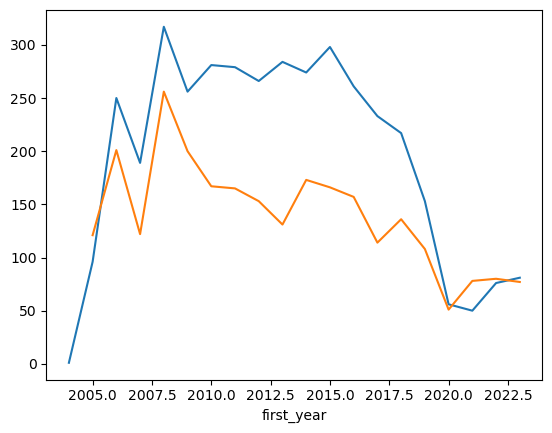

In [174]:
non_udu.groupby('first_year').size().plot(label='Non-UDU')
udu.groupby('first_year').size().plot(label='UDU')

In [163]:
import seaborn as sns

udu.groupby('first_year')['nature_of_complaint'].value_counts(normalize=False).unstack().plot.bar(stacked=True)

<Axes: xlabel='first_year'>

Error in callback <function flush_figures at 0x18dec9e10> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

<Axes: xlabel='last_year'>

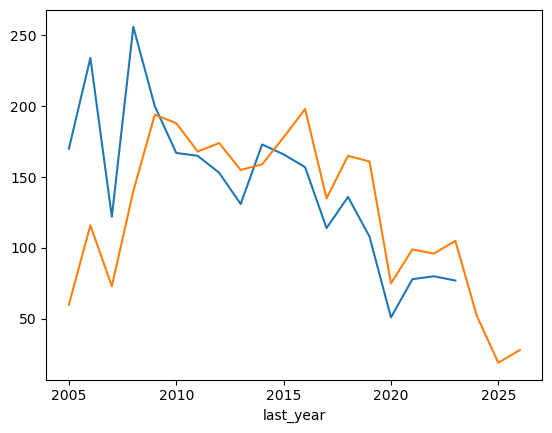

In [ ]:
udu.first_year.value_counts().sort_index().plot()
udu.last_year.value_counts().sort_index().plot()


In [176]:
udu.columns


Index(['case_id', 'AIN', 'ain_csv', 'apn_page', 'apn_match', 'case_type',
       'inspector', 'total_units', 'council_district', 'census_tract',
       'regional_office', 'official_address', 'nature_of_complaint',
       'activity_n', 'activity_first_date', 'activity_last_date',
       'activity_list', 'fetch_status', 'http_code', 'fetched_at_utc',
       'relates_to_unpermitted_structure', 'dwelling_specific',
       'complaint_category', 'latest_status', 'latest_date', 'status_bucket',
       'order_issued_ever', 'no_violations_observed_ever', 'first_year',
       'last_year', 'zip5', 'irs_returns_2022', 'irs_agi_thousands_2022',
       'irs_mean_agi_per_return_2022', 'irs_zip_is_geographic',
       'irs_income_matched_2022'],
      dtype='object')

In [177]:
udu[['case_id', 'AIN', 'ain_csv', 'apn_page', 'apn_match']]

,case_id,AIN,ain_csv,apn_page,apn_match
320,2427,5049029019,5049029019,5.049029e+09,yes
464,3411,5121020029,5121020029,5.121020e+09,yes
479,3653,5114032007,5114032007,5.114032e+09,yes
562,4026,7467028014,7467028014,7.467028e+09,yes
585,4013,5131011029,5131011029,5.131011e+09,yes
...,...,...,...,...,...
170398,878523,5404010030,5404010030,5.404010e+09,yes
170415,877454,5191028030,5191028030,5.191028e+09,yes
170446,878081,5206021003,5206021003,5.206021e+09,yes
170521,869894,5542011005,5542011005,5.542011e+09,yes


In [119]:
udu.sample(100)[['case_id','AIN','nature_of_complaint']]#']]

,case_id,AIN,nature_of_complaint
117182,640476,5521006014,"Floor covering defective, missing, or unsafe, ..."
126037,683370,5127011025,"Unapproved stove or range vent, Unapproved sto..."
98236,544745,4294004010,"Unapproved Unit(s), Change of use/occupancy wi..."
32599,195970,4402009004,"Unapproved Unit(s), Change of use/occupancy wi..."
5160,26635,5190012026,Illegal garage conversion into a dwelling unit.
...,...,...,...
166318,862117,5119018001,"Electrical receptacles painted and unusuable, ..."
46028,270327,6034021003,Unapproved Unit(s)
55009,321129,5464024013,Change of use/occupancy without Building permi...
31989,191013,4260032036,"Construction in progress without permits, Unap..."


In [115]:
data_fp = '/Users/adamswietek/Documents/NDSC_HiddenHousing/data/03_processed/method_comparison/method1_floor_area_similarity_2017.csv'

data = pd.read_csv(data_fp, dtype=str, low_memory=False)

In [180]:
non_udu.to_csv('violation_non_udu.csv')

In [179]:
udu.to_csv('violation_udu.csv')

In [123]:
def normalize_ain(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.replace(r"\D", "", regex=True)
        .str.zfill(10)
    )

udu = udu.copy()
data = data.copy()

udu["AIN"] = normalize_ain(udu["AIN"])
data["AIN"] = normalize_ain(data["AIN"])

merged = pd.merge(
    udu,
    data,
    how="inner",
    on="AIN",
    validate="m:1",
)

print(merged.shape)

(2533, 44)


## LARIAC versus assessor area with violation-derived UDUs

Repeat the main relationship figure from notebook 01 and add the violation-derived UDU parcels contained in `merged`, the filtered complaint–Method 1 dataset created above. Repeated complaint rows are collapsed to unique AINs before plotting. Blue open circles identify violation-derived UDUs; red × marks identify known UDUs from the current UDU report. A parcel in both groups displays both symbols.

In [126]:
import textwrap

import numpy as np

UDU_REPORT_FP = (
    '/Users/adamswietek/Documents/NDSC_HiddenHousing/'
    'data/01_source/UDU Report 02_10_2026.csv'
)

# `merged` is the authoritative filtered violation-UDU dataset.
violation_udu_ains = set(normalize_ain(merged['AIN']).dropna())

known_udu_report = pd.read_csv(
    UDU_REPORT_FP,
    usecols=['assessor_parcel_number'],
    dtype=str,
    encoding='utf-8-sig',
)
known_udu_ains = set(
    normalize_ain(known_udu_report['assessor_parcel_number']).dropna()
)

method1_plot = data.copy()
method1_plot['AIN'] = normalize_ain(method1_plot['AIN'])
if method1_plot['AIN'].duplicated().any():
    raise ValueError('Method 1 data must contain one row per AIN.')

for column in ['assessor_sqftmain', 'lariac_floor_area_continuous_sqft']:
    method1_plot[column] = pd.to_numeric(
        method1_plot[column], errors='coerce'
    )

method1_plot['is_known_udu'] = method1_plot['AIN'].isin(known_udu_ains)
method1_plot['is_violation_udu'] = (
    method1_plot['AIN'].isin(violation_udu_ains)
)
method1_plot['is_known_and_violation_udu'] = (
    method1_plot['is_known_udu'] & method1_plot['is_violation_udu']
)
method1_plot = method1_plot.loc[
    method1_plot['assessor_sqftmain'].gt(0)
    & method1_plot['lariac_floor_area_continuous_sqft'].gt(0)
    & method1_plot['SpecificUseType'].notna()
].copy()

plot_use_type_summary = (
    method1_plot.groupby('SpecificUseType')
    .agg(
        parcels=('AIN', 'size'),
        known_udu=('is_known_udu', 'sum'),
        violation_udu=('is_violation_udu', 'sum'),
        overlap=('is_known_and_violation_udu', 'sum'),
    )
    .sort_values(['known_udu', 'parcels'], ascending=False)
)
modeled_use_types = plot_use_type_summary.index.tolist()

display(pd.Series({
    'Unique violation-UDU AINs in merged': len(violation_udu_ains),
    'Violation-UDU AINs in Method 1': int(
        method1_plot['is_violation_udu'].sum()
    ),
    'Known UDU AINs in Method 1': int(method1_plot['is_known_udu'].sum()),
    'AINs in both groups': int(
        method1_plot['is_known_and_violation_udu'].sum()
    ),
}).to_frame('count'))
display(plot_use_type_summary.reset_index())

,count
Unique violation-UDU AINs,2510
Violation-UDU AINs in Method 1,2319
Known UDU AINs in Method 1,409
AINs in both groups,48


,SpecificUseType,parcels,known_udu,violation_udu,overlap
0,Five or More Units or Apartments (Any Combinat...,29213,180,490,20
1,"Double, Duplex, or Two Units",42868,90,1040,16
2,Three Units (Any Combination),13650,74,374,7
3,Four Units (Any Combination),13396,39,293,4
4,Store Combination,5216,16,74,1
5,Single Family Residence,430850,10,48,0


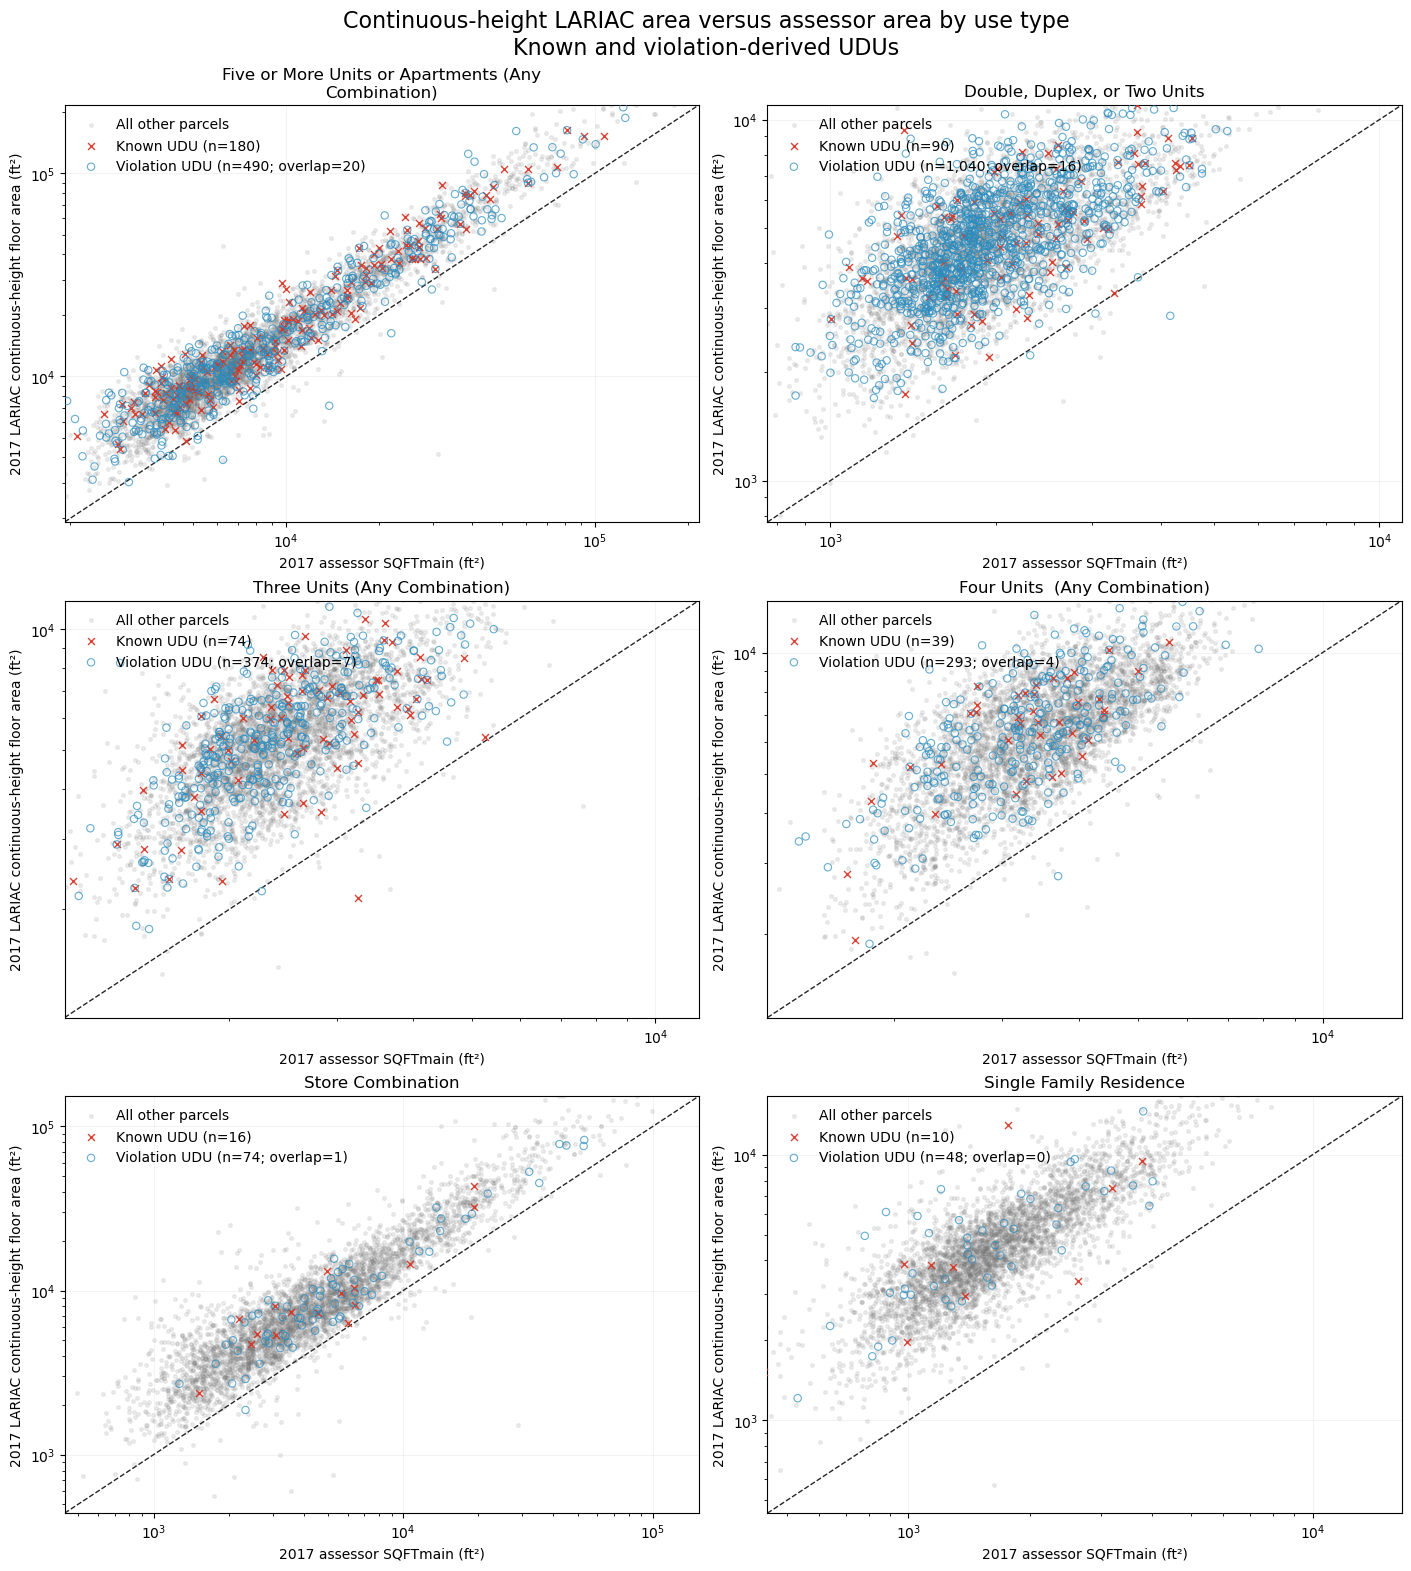

In [127]:
ncols = 2
nrows = int(np.ceil(len(modeled_use_types) / ncols))
fig, axes = plt.subplots(
    nrows, ncols, figsize=(14, 5.2 * nrows), constrained_layout=True
)
axes = np.atleast_1d(axes).ravel()

for ax, use_type in zip(axes, modeled_use_types):
    group = method1_plot.loc[
        method1_plot['SpecificUseType'].eq(use_type)
    ]
    special = group['is_known_udu'] | group['is_violation_udu']
    other = group.loc[~special]
    if len(other) > 4_000:
        other = other.sample(4_000, random_state=42)
    known = group.loc[group['is_known_udu']]
    violation = group.loc[group['is_violation_udu']]
    overlap_n = int(group['is_known_and_violation_udu'].sum())

    ax.scatter(
        other['assessor_sqftmain'],
        other['lariac_floor_area_continuous_sqft'],
        s=7, alpha=0.12, color='#737373', rasterized=True,
        label='All other parcels',
    )
    ax.scatter(
        known['assessor_sqftmain'],
        known['lariac_floor_area_continuous_sqft'],
        s=25, alpha=0.9, color='#d7301f', marker='x', linewidth=1.0,
        zorder=3, label=f'Known UDU (n={len(known):,})',
    )
    ax.scatter(
        violation['assessor_sqftmain'],
        violation['lariac_floor_area_continuous_sqft'],
        s=28, alpha=0.72, facecolors='none', edgecolors='#2b8cbe',
        marker='o', linewidth=0.8, zorder=4, rasterized=True,
        label=(
            f'Violation UDU (n={len(violation):,}; '
            f'overlap={overlap_n:,})'
        ),
    )

    values = pd.concat([
        group['assessor_sqftmain'],
        group['lariac_floor_area_continuous_sqft'],
    ]).dropna()
    lower = max(10, float(values.quantile(0.001)))
    upper = float(values.quantile(0.995))
    ax.plot(
        [lower, upper], [lower, upper], '--',
        color='#252525', linewidth=1,
    )
    ax.set(
        xscale='log', yscale='log',
        xlim=(lower, upper), ylim=(lower, upper),
    )
    ax.set_title('\n'.join(textwrap.wrap(use_type, 42)))
    ax.set_xlabel('2017 assessor SQFTmain (ft²)')
    ax.set_ylabel('2017 LARIAC continuous-height floor area (ft²)')
    ax.grid(alpha=0.15)
    ax.legend(frameon=False, loc='upper left')

for ax in axes[len(modeled_use_types):]:
    ax.remove()

fig.suptitle(
    'Continuous-height LARIAC area versus assessor area by use type\n'
    'Known and violation-derived UDUs',
    fontsize=16,
)
plt.show()

## Economic and spatial pattern of violation-derived UDUs

The analysis universe is restricted to unique AINs that (1) have at least one complaint and (2) appear in the Method 1 parcel table. The outcome is membership in `merged`, the filtered violation-UDU dataset. This makes the numerator and denominator consistent.

IRS mean AGI is a 2022 ZIP-level contextual measure. TCAC/HCD opportunity features are 2021 tract-level contextual measures. The reported shares are therefore **the share of complaint parcels classified as violation UDUs**, not the prevalence of unpermitted dwellings among all parcels or households. Complaint behavior, inspection, enforcement, and Method 1 eligibility can all affect these patterns.

In [133]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy.stats import spearmanr

TCAC_OPPORTUNITY_FP = (
    '/Users/adamswietek/Documents/NDSC_HiddenHousing/'
    'data/01_source/tcac_hcd_2021_opportunity_map.gpkg'
)


def normalize_tract_code(values):
    text = values.astype('string').str.strip()
    text = text.str.replace(r'\.0+$', '', regex=True)
    digits = text.str.replace(r'\D', '', regex=True)
    tract = digits.str[-6:].str.zfill(6)
    return tract.mask(text.isna() | text.eq('') | digits.eq(''))


def first_valid(series):
    values = series.dropna()
    return values.iloc[0] if len(values) else pd.NA


complaint_context = complaints.copy()
complaint_context['AIN'] = normalize_ain(complaint_context['AIN'])
complaint_context['tract_6'] = normalize_tract_code(
    complaint_context['census_tract']
)
complaint_context['GEOID_TRACT'] = (
    '06037' + complaint_context['tract_6']
).mask(complaint_context['tract_6'].isna())

method1_ains = set(normalize_ain(data['AIN']).dropna())
violation_udu_ains = set(normalize_ain(merged['AIN']).dropna())
complaint_context = complaint_context.loc[
    complaint_context['AIN'].isin(method1_ains)
].copy()

complaint_parcels = (
    complaint_context.groupby('AIN', as_index=False)
    .agg(
        complaint_cases=('case_id', 'nunique'),
        zip5=('zip5', first_valid),
        GEOID_TRACT=('GEOID_TRACT', first_valid),
        irs_mean_agi_per_return_2022=(
            'irs_mean_agi_per_return_2022', 'median'
        ),
    )
)
complaint_parcels['is_violation_udu'] = (
    complaint_parcels['AIN'].isin(violation_udu_ains)
)

tcac_raw = gpd.read_file(
    TCAC_OPPORTUNITY_FP, layer='tcac_opportunity'
)
tcac_raw['opp_cat'] = (
    tcac_raw['opp_cat'].astype('string').str.strip().replace('', pd.NA)
)

def modal_value(series):
    modes = series.dropna().mode()
    return modes.iloc[0] if len(modes) else pd.NA

# Fourteen GEOIDs occur more than once in the source. Aggregate them to
# one tract before joining so they cannot duplicate complaint parcels.
tcac_attributes = (
    tcac_raw.groupby('GEOID_TRACT', as_index=False)
    .agg(
        opp_cat=('opp_cat', modal_value),
        opp_econ=('opp_econ', 'mean'),
        opp_env=('opp_env', 'mean'),
        opp_educ=('opp_educ', 'mean'),
        opp_index=('opp_index', 'mean'),
        tcac_source_rows=('GEOID_TRACT', 'size'),
    )
)
tcac_geometry = (
    tcac_raw[['GEOID_TRACT', 'geometry']]
    .dissolve(by='GEOID_TRACT', as_index=False)
)
tcac_map = tcac_geometry.merge(
    tcac_attributes, on='GEOID_TRACT', how='left', validate='one_to_one'
)
opportunity_columns = [
    'GEOID_TRACT', 'opp_cat', 'opp_econ', 'opp_env',
    'opp_educ', 'opp_index',
]
complaint_parcels = complaint_parcels.merge(
    tcac_attributes[opportunity_columns],
    on='GEOID_TRACT', how='left', validate='m:1',
)

income = complaint_parcels['irs_mean_agi_per_return_2022']
complaint_parcels['income_decile'] = (
    pd.qcut(income, q=10, labels=False, duplicates='drop') + 1
)
complaint_parcels['income_quintile'] = pd.qcut(
    income, q=5, labels=['Q1 lowest', 'Q2', 'Q3', 'Q4', 'Q5 highest'],
    duplicates='drop',
)

context_coverage = pd.Series({
    'Complaint AINs in Method 1 universe': len(complaint_parcels),
    'Violation-UDU AINs from merged': int(
        complaint_parcels['is_violation_udu'].sum()
    ),
    'AINs matched to IRS ZIP income': int(income.notna().sum()),
    'AINs matched to opportunity tract': int(
        complaint_parcels['opp_cat'].notna().sum()
    ),
    'AINs matched to both contexts': int(
        complaint_parcels[[
            'irs_mean_agi_per_return_2022', 'opp_cat'
        ]].notna().all(axis=1).sum()
    ),
})
display(context_coverage.to_frame('count'))

MergeError: Merge keys are not unique in right dataset; not a many-to-one merge

In [ ]:
income_summary = (
    complaint_parcels.dropna(subset=['income_decile'])
    .groupby('income_decile', observed=True)
    .agg(
        complaint_parcels=('AIN', 'size'),
        violation_udus=('is_violation_udu', 'sum'),
        violation_share=('is_violation_udu', 'mean'),
        median_income=('irs_mean_agi_per_return_2022', 'median'),
    )
    .reset_index()
)
income_summary['standard_error'] = np.sqrt(
    income_summary['violation_share']
    * (1 - income_summary['violation_share'])
    / income_summary['complaint_parcels']
)
income_summary['ci_low'] = (
    income_summary['violation_share']
    - 1.96 * income_summary['standard_error']
).clip(lower=0)
income_summary['ci_high'] = (
    income_summary['violation_share']
    + 1.96 * income_summary['standard_error']
).clip(upper=1)

opportunity_order = [
    'High Segregation & Poverty',
    'Low Resource',
    'Moderate Resource',
    'Moderate Resource (Rapidly Changing)',
    'High Resource',
    'Highest Resource',
]
opportunity_summary = (
    complaint_parcels.dropna(subset=['opp_cat'])
    .groupby('opp_cat')
    .agg(
        complaint_parcels=('AIN', 'size'),
        violation_udus=('is_violation_udu', 'sum'),
        violation_share=('is_violation_udu', 'mean'),
        median_income=('irs_mean_agi_per_return_2022', 'median'),
    )
    .reindex(opportunity_order)
    .dropna(subset=['complaint_parcels'])
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
axes[0].errorbar(
    income_summary['income_decile'],
    income_summary['violation_share'],
    yerr=[
        income_summary['violation_share'] - income_summary['ci_low'],
        income_summary['ci_high'] - income_summary['violation_share'],
    ],
    color='#2b8cbe', marker='o', linewidth=1.5, capsize=3,
)
axes[0].set(
    xlabel='IRS 2022 ZIP mean-AGI decile (low → high)',
    ylabel='Violation-UDU share among complaint parcels',
    title='Economic gradient', xticks=range(1, 11),
)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].grid(alpha=0.2)

colors = sns.color_palette('RdYlBu', n_colors=len(opportunity_summary))
axes[1].barh(
    opportunity_summary.index,
    opportunity_summary['violation_share'],
    color=colors, edgecolor='white',
)
axes[1].invert_yaxis()
axes[1].set(
    xlabel='Violation-UDU share among complaint parcels',
    ylabel='', title='TCAC/HCD opportunity category',
)
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].grid(axis='x', alpha=0.2)
for y, (_, row) in enumerate(opportunity_summary.iterrows()):
    axes[1].text(
        row['violation_share'] + 0.001, y,
        f"{row['violation_share']:.1%}  (n={int(row['complaint_parcels']):,})",
        va='center', fontsize=8,
    )

fig.suptitle(
    'Violation-derived UDUs by ZIP income and neighborhood opportunity',
    fontsize=15,
)
plt.show()

display(income_summary)
display(opportunity_summary.reset_index())

In [ ]:
two_way = (
    complaint_parcels.dropna(subset=['income_quintile', 'opp_cat'])
    .groupby(['opp_cat', 'income_quintile'], observed=True)
    .agg(
        complaint_parcels=('AIN', 'size'),
        violation_share=('is_violation_udu', 'mean'),
    )
    .reset_index()
)
share_matrix = (
    two_way.pivot(
        index='opp_cat', columns='income_quintile',
        values='violation_share',
    )
    .reindex(opportunity_order)
)
count_matrix = (
    two_way.pivot(
        index='opp_cat', columns='income_quintile',
        values='complaint_parcels',
    )
    .reindex(opportunity_order)
)

plt.figure(figsize=(10, 5.5))
sns.heatmap(
    share_matrix.mul(100),
    mask=count_matrix.lt(50) | share_matrix.isna(),
    annot=True, fmt='.1f', cmap='YlOrRd', linewidths=0.5,
    cbar_kws={'label': 'Violation-UDU share (%)'},
)
plt.title(
    'Violation-UDU share by opportunity category and ZIP-income quintile\n'
    'Cells with fewer than 50 complaint parcels are suppressed'
)
plt.xlabel('IRS 2022 ZIP mean-AGI quintile')
plt.ylabel('TCAC/HCD opportunity category')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
tract_context = (
    complaint_parcels.dropna(subset=['GEOID_TRACT'])
    .groupby('GEOID_TRACT', as_index=False)
    .agg(
        complaint_parcels=('AIN', 'size'),
        violation_udus=('is_violation_udu', 'sum'),
        violation_share=('is_violation_udu', 'mean'),
        median_zip_income=('irs_mean_agi_per_return_2022', 'median'),
        opp_econ=('opp_econ', 'first'),
        opp_env=('opp_env', 'first'),
        opp_educ=('opp_educ', 'first'),
        opp_index=('opp_index', 'first'),
    )
)
MIN_COMPLAINT_PARCELS_PER_TRACT = 20
stable_tracts = tract_context.loc[
    tract_context['complaint_parcels'].ge(
        MIN_COMPLAINT_PARCELS_PER_TRACT
    )
].copy()

correlation_rows = []
for feature in [
    'median_zip_income', 'opp_econ', 'opp_env', 'opp_educ', 'opp_index'
]:
    valid = stable_tracts[['violation_share', feature]].dropna()
    rho, p_value = spearmanr(
        valid['violation_share'], valid[feature]
    )
    correlation_rows.append({
        'context_feature': feature,
        'tracts': len(valid),
        'spearman_rho': rho,
        'p_value': p_value,
    })
tract_correlation_summary = pd.DataFrame(correlation_rows)
display(
    tract_correlation_summary.style.format({
        'spearman_rho': '{:.3f}', 'p_value': '{:.3g}',
    })
)

In [ ]:
tract_map = tcac_map.merge(
    tract_context, on='GEOID_TRACT', how='left', validate='1:1'
)
tract_map['violation_udus'] = tract_map['violation_udus'].fillna(0)
stable_map = tract_map.loc[
    tract_map['complaint_parcels'].ge(
        MIN_COMPLAINT_PARCELS_PER_TRACT
    )
].copy()
stable_map['violation_share_pct'] = (
    stable_map['violation_share'] * 100
)

fig, axes = plt.subplots(1, 2, figsize=(15, 8), constrained_layout=True)
tcac_map.plot(ax=axes[0], color='#f2f2f2', edgecolor='white', linewidth=0.15)
tract_map.plot(
    ax=axes[0], column='violation_udus', cmap='magma',
    vmin=0, vmax=tract_map['violation_udus'].quantile(0.99),
    legend=True, edgecolor='none',
    legend_kwds={'label': 'Violation-UDU AINs (capped at 99th percentile)'},
)
axes[0].set_title('Violation-derived UDU count')

tcac_map.plot(ax=axes[1], color='#f2f2f2', edgecolor='white', linewidth=0.15)
stable_map.plot(
    ax=axes[1], column='violation_share_pct', cmap='YlOrRd',
    vmin=0, vmax=stable_map['violation_share_pct'].quantile(0.95),
    legend=True, edgecolor='none',
    legend_kwds={
        'label': 'Share among complaint parcels (capped at 95th percentile)',
        'format': '%.0f%%',
    },
)
axes[1].set_title(
    f'Violation-UDU share (tracts with ≥{MIN_COMPLAINT_PARCELS_PER_TRACT} complaint AINs)'
)
for ax in axes:
    ax.set_axis_off()
fig.suptitle(
    'Spatial distribution of violation-derived UDUs', fontsize=15
)
plt.show()

## Parcel-year UDU violation outcomes

Combine `udu` and `non_udu` into a parcel-year table keyed by normalized `AIN` and the complaint case's `first_year`. `udu_violation` equals one when at least one qualifying case for that parcel-year appears in `udu`. `udu_nonobserved` equals one when at least one qualifying case appears in `non_udu` (the case history contains “No violations observed”).

The indicators are intentionally independent. A parcel-year can have both values equal to one when separate cases—or different events in one case—produce conflicting evidence. The current `*_ever` fields do not provide the exact event year, so `year` represents the case-opening year rather than necessarily the year an order or no-violation event occurred.

In [181]:
import numpy as np


def first_nonmissing(series):
    values = series.dropna()
    return values.iloc[0] if len(values) else pd.NA


def outcome_rows(frame, *, violation, nonobserved):
    columns = [
        'case_id', 'AIN', 'first_year', 'census_tract',
        'council_district', 'zip5',
        'irs_mean_agi_per_return_2022',
    ]
    result = frame[[c for c in columns if c in frame.columns]].copy()
    result['AIN'] = normalize_ain(result['AIN'])
    result['year'] = pd.to_numeric(
        result.pop('first_year'), errors='coerce'
    ).astype('Int64')
    result['udu_violation'] = np.int8(violation)
    result['udu_nonobserved'] = np.int8(nonobserved)
    return result.dropna(subset=['AIN', 'year'])


udu_outcome_cases = pd.concat(
    [
        outcome_rows(udu, violation=1, nonobserved=0),
        outcome_rows(non_udu, violation=0, nonobserved=1),
    ],
    ignore_index=True,
)
# Remove exact repeats within an outcome source while retaining a case that
# legitimately contributes to both binary indicators.
udu_outcome_cases = udu_outcome_cases.drop_duplicates([
    'AIN', 'year', 'case_id', 'udu_violation', 'udu_nonobserved'
])

context_aggregations = {
    column: (column, first_nonmissing)
    for column in [
        'census_tract', 'council_district', 'zip5',
        'irs_mean_agi_per_return_2022',
    ]
    if column in udu_outcome_cases.columns
}

udu_parcel_year = (
    udu_outcome_cases.groupby(['AIN', 'year'], as_index=False)
    .agg(
        udu_violation=('udu_violation', 'max'),
        udu_nonobserved=('udu_nonobserved', 'max'),
        violation_case_count=('udu_violation', 'sum'),
        nonobserved_case_count=('udu_nonobserved', 'sum'),
        complaint_case_count=('case_id', 'nunique'),
        **context_aggregations,
    )
)
for column in ['udu_violation', 'udu_nonobserved']:
    udu_parcel_year[column] = udu_parcel_year[column].astype('int8')

udu_parcel_year['udu_outcome_conflict'] = (
    udu_parcel_year['udu_violation'].eq(1)
    & udu_parcel_year['udu_nonobserved'].eq(1)
).astype('int8')
udu_parcel_year['udu_outcome'] = np.select(
    [
        udu_parcel_year['udu_outcome_conflict'].eq(1),
        udu_parcel_year['udu_violation'].eq(1),
        udu_parcel_year['udu_nonobserved'].eq(1),
    ],
    ['both', 'violation', 'no_violations_observed'],
    default='neither',
)

parcel_year_summary = pd.Series({
    'Parcel-year rows': len(udu_parcel_year),
    'Unique AINs': udu_parcel_year['AIN'].nunique(),
    'Parcel-years with violation': int(
        udu_parcel_year['udu_violation'].sum()
    ),
    'Parcel-years with no violations observed': int(
        udu_parcel_year['udu_nonobserved'].sum()
    ),
    'Parcel-years with both indicators': int(
        udu_parcel_year['udu_outcome_conflict'].sum()
    ),
})
display(parcel_year_summary.to_frame('count'))
display(udu_parcel_year.head())

,count
Parcel-year rows,5934
Unique AINs,5249
Parcel-years with violation,2586
Parcel-years with no violations observed,3626
Parcel-years with both indicators,278


,AIN,year,udu_violation,udu_nonobserved,violation_case_count,nonobserved_case_count,complaint_case_count,census_tract,council_district,zip5,irs_mean_agi_per_return_2022,udu_outcome_conflict,udu_outcome
0,2023008009,2022,1,0,1,0,1,134303.0,3.0,91303,55491.534392,0,violation
1,2024012018,2022,0,1,0,1,1,134303.0,3.0,91303,55491.534392,0,no_violations_observed
2,2040027024,2020,0,1,0,1,1,137203.0,3.0,91367,155674.218052,0,no_violations_observed
3,2041010031,2022,0,1,0,1,1,137301.0,3.0,<NA>,<NA>,0,no_violations_observed
4,2042007014,2023,1,0,1,0,1,137000.0,3.0,91367,155674.218052,0,violation


In [183]:
udu_parcel_year.to_csv('udu_violation_outcome_parcel_year.csv')

In [21]:
complaints.AIN.nunique()

52259

In [24]:
complaints.complaint_category.unique()

array(['not_unpermitted_related', 'work_without_permits',
       'illegal_business_use', 'unpermitted_construction',
       'unapproved_unit', 'illegal_conversion', 'garage_conversion',
       'unapproved_trade_work', 'unpermitted_addition',
       'other_unpermitted', 'not_fetched', 'change_of_use',
       'living_in_garage'], dtype=object)

In [ ]:
unapproved_unit_complaints = complaints.loc[
    complaints['nature_of_complaint'].str.contains(
        r'\bunapproved\s+units?\b', case=False, na=False
    )
].copy()

unapproved_unit_complaints

In [36]:
complaints.query('relates_to_unpermitted_structure == True')['nature_of_complaint'].unique()

array(['POSSIBLE ILLEGAL CONVERSION W/O PROPER PERMITS.',
       'COMP #4, CONSTRUCTION W/O PERMITS (BUILDING WALL AROUND PROPERTY 6-7 FEET TALL',
       'Running an illegal rent salon in the a unit.', ...,
       'Lack of adequate flow of hot and/or cold running water, Room heating appliance missing or defective, Lack of adequate number of receptacles for garbage and rubbish, Exit door lock or latch has double-keyed lock, padlock, or slide bolt latch, Floor covering defective, missing, or unsafe, Smoke Detector(s) missing, defective, or not hard wired, Exit door(s) require maintenance, Plumbing work or water heater installation done without permit or inspection approval',
       'Dampness in rooms, Unit in unsafe and/or unclean condition, Plumbing fixtures defective, broken, or missing, Inadequate, unapproved, or missing water supply, Trash, debris, or rodents on premises, Defective or missing heating facilities, Termites, dry rot and/or decayed wood., Windows, doors, cabinets, and fr

In [51]:
unapproved_unit_complaints = complaints.loc[
    complaints['nature_of_complaint'].str.contains(
        r'\bunapproved unit\s?\b', case=False, na=False
    )
].copy()
pd.crosstab(unapproved_unit_complaints['no_violations_observed_ever'], 
            unapproved_unit_complaints['order_issued_ever'], margins=True)

order_issued_ever,False,True,All
no_violations_observed_ever,,,
False,391,2422,2813
True,3717,46,3763
All,4108,2468,6576


In [ ]:
unapproved_unit_complaints.groupby('AIN')[['no_violations_observed_ever','order_issued_ever']].agg('sum')

,no_violations_observed_ever,order_issued_ever
count,5245.000000,5245.000000
mean,0.717445,0.470543
std,0.704845,0.580101
min,0.000000,0.000000
25%,0.000000,0.000000
50%,1.000000,0.000000
75%,1.000000,1.000000
max,7.000000,6.000000


In [55]:
def join_unique_complaints(values):
    complaints = (
        values.dropna().astype('string').str.strip()
    )
    return ' | '.join(dict.fromkeys(
        value for value in complaints if value
    ))


ain_level_unapproved_unit_complaints = (
    unapproved_unit_complaints
    .dropna(subset=['AIN'])
    .groupby('AIN', as_index=False)
    .agg(
        no_violation_ever=(
            'no_violations_observed_ever', 'any'
        ),
        order_issued_ever=('order_issued_ever', 'any'),
        complaint_start_year=('first_year', 'min'),
        nature_of_associated_complaint=(
            'nature_of_complaint', join_unique_complaints
        ),
    )
)
ain_level_unapproved_unit_complaints['complaint_start_year'] = (
    ain_level_unapproved_unit_complaints['complaint_start_year']
    .astype('Int64')
)

ain_level_unapproved_unit_complaints

,AIN,no_violation_ever,order_issued_ever,complaint_start_year,nature_of_associated_complaint
0,2023008009,False,True,2022,Change of use/occupancy without Building permi...
1,2024012018,True,False,2022,Deteriorated or missing caulking seal between ...
2,2040027024,True,False,2020,"Unit in unsafe and/or unclean condition, Unapp..."
3,2041010031,True,False,2022,"Unapproved Unit(s), Electric"
4,2042007014,False,True,2023,Change of use/occupancy without Building permi...
...,...,...,...,...,...
5240,7467017021,True,False,2012,"Unapproved Unit(s) | Unapproved Unit(s), Unapp..."
5241,7467021015,False,False,2015,Unapproved Unit(s)
5242,7467026012,True,False,2007,"Construction performed without permits, Unappr..."
5243,7467029002,True,False,2006,Unapproved Unit(s)


In [59]:
ain_level_unapproved_unit_complaints.nature_of_associated_complaint.unique().tolist()

['Change of use/occupancy without Building permit and Certificate of Occupancy, Unapproved Unit(s), Provide Tenant Habitability Plan to the Los Angeles Housing Dept for any/all work impacting the tenants habitability., Construction work impacting tenant habitability, Building and/or premises unsafe, or unclean, Windows, doors, cabinets, and frames not operable, defective, missing, and/or unsanitary, Plaster/drywall wall/ceiling covering defective, deteriorated, or paint is peeling, Floor covering defective, missing, or unsafe',
 'Deteriorated or missing caulking seal between plumbing fixture(s) and walls or floors, Plumbing fixtures defective, broken, or missing, Lack of adequate flow of hot and/or cold running water, Unapproved Unit(s), Change of use/occupancy without Building permit and Certificate of Occupancy',
 'Unit in unsafe and/or unclean condition, Unapproved Unit(s), Construction performed without permits',
 'Unapproved Unit(s), Electric',
 'Change of use/occupancy without Bu

In [57]:
pd.crosstab(
    ain_level_unapproved_unit_complaints['no_violation_ever'],
    ain_level_unapproved_unit_complaints['order_issued_ever'],
    margins=True,
)

order_issued_ever,False,True,All
no_violation_ever,,,
False,251,1790,2041
True,2719,485,3204
All,2970,2275,5245


In [60]:
ain_level_unapproved_unit_complaints.to_csv('ain_level_unapproved_unit_complaints.csv', index=False)